# CAT No. 2 — Image Classification Using PyTorch

## Project objective

This notebook builds a 10-class image classifier using PyTorch. It learns from `Train.csv` and predicts labels for the image IDs in `Test.csv`.

The supplied data, as inspected in the original run, contains **4,000 labelled training images** (400 per class), **46,000 unlabelled test images**, and RGB images of size **32 × 32**. `Train.csv` contains `id` and `label`; `Test.csv` contains `id` only.

### Workflow
1. Locate and load the CSV files and images.
2. Inspect the labels, class balance, and sample images.
3. Encode labels and create a stratified training/validation split.
4. Build a custom `torch.utils.data.Dataset` and PyTorch DataLoaders.
5. Apply augmentation to training images only.
6. Define a convolutional neural network (CNN).
7. Select hyperparameters with Optuna's TPE sampler.
8. Train and evaluate on a held-out validation partition.
9. Retrain the selected architecture using all labelled images.
10. Predict the test labels and export `Submission.csv`.

**Important:** `Test.csv` does not contain true labels. This notebook can measure validation accuracy, but cannot calculate true test accuracy.

## 1. Environment and libraries

The notebook uses PyTorch, torchvision, pandas, NumPy, Pillow, Matplotlib, scikit-learn, and Optuna. Select the same `.venv` kernel that was used to run the original project.

If imports fail because a package is missing, install only the missing packages from the activated virtual-environment terminal. For example:

```bash
python -m pip install optuna scikit-learn pillow matplotlib
```



In [1]:
from pathlib import Path
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import optuna
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42

def set_seed(seed=SEED):
    """Set random seeds for more repeatable experiments."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.4.1+cpu
Device: cpu


## 2. Dataset location and loading

In the supplied project, the image folder is named `train` inside `Trial`. It contains image files referenced by both CSV files. The folder name does not mean every image in it has a training label.

The code checks `dataset/Trial` first, which matches the folder structure used in your project. If that location is different, it searches below the current notebook directory for a folder containing `Train.csv`, `Test.csv`, and a `train` image directory. If no unique location is found, set `DATA_ROOT` manually to the directory containing those three items.

In [2]:
EXPECTED_DATA_ROOT = Path("dataset") / "Trial"

if (
    (EXPECTED_DATA_ROOT / "Train.csv").exists()
    and (EXPECTED_DATA_ROOT / "Test.csv").exists()
    and (EXPECTED_DATA_ROOT / "train").is_dir()
):
    DATA_ROOT = EXPECTED_DATA_ROOT
else:
    matches = []
    for train_csv_path in Path.cwd().rglob("Train.csv"):
        candidate = train_csv_path.parent
        if (candidate / "Test.csv").exists() and (candidate / "train").is_dir():
            matches.append(candidate)

    if len(matches) == 1:
        DATA_ROOT = matches[0]
    elif len(matches) > 1:
        raise RuntimeError(
            "Multiple dataset folders found. Set DATA_ROOT manually to the correct one."
        )
    else:
        raise FileNotFoundError(
            "Dataset not found. Extract the ZIP and set DATA_ROOT to the folder "
            "containing Train.csv, Test.csv, and the train image directory."
        )

TRAIN_CSV = DATA_ROOT / "Train.csv"
TEST_CSV = DATA_ROOT / "Test.csv"
IMAGE_DIR = DATA_ROOT / "train"

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

if not {"id", "label"}.issubset(train_df.columns):
    raise ValueError("Train.csv must contain 'id' and 'label' columns.")
if "id" not in test_df.columns:
    raise ValueError("Test.csv must contain an 'id' column.")

print("Dataset folder:", DATA_ROOT.resolve())
print("Image folder:", IMAGE_DIR.resolve())
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("\\nTraining CSV preview:")
display(train_df.head())
print("\\nTest CSV preview:")
display(test_df.head())

Dataset folder: C:\Users\Admin\Downloads\ASS2\dataset\Trial
Image folder: C:\Users\Admin\Downloads\ASS2\dataset\Trial\train
Training rows: 4000
Test rows: 46000
\nTraining CSV preview:


,id,label
0,44011,truck
1,40500,deer
2,19479,horse
3,3682,ship
4,7367,ship


\nTest CSV preview:


,id,label
0,33680,NaN
1,24631,NaN
2,34739,NaN
3,15922,NaN
4,44282,NaN


## 3. Inspect the data

The `id` column identifies an image file, while `label` is the correct category for a training image. First, check missing values and duplicate IDs. Then count the examples in each class.

The class-count chart helps identify class imbalance. In the supplied data, each of the ten classes has 400 examples, so the training set is balanced. A balanced class distribution makes overall accuracy a useful first metric, but class-level precision, recall, and F1-score are also reported later.

The sample image grid checks that IDs resolve to image files and that images can be opened as RGB pictures.

Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      4000 non-null   int64 
 1   label   4000 non-null   object
dtypes: int64(1), object(1)
memory usage: 62.6+ KB
\nMissing values:
id       0
label    0
dtype: int64
Duplicate training IDs: 0
\nClass counts:
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


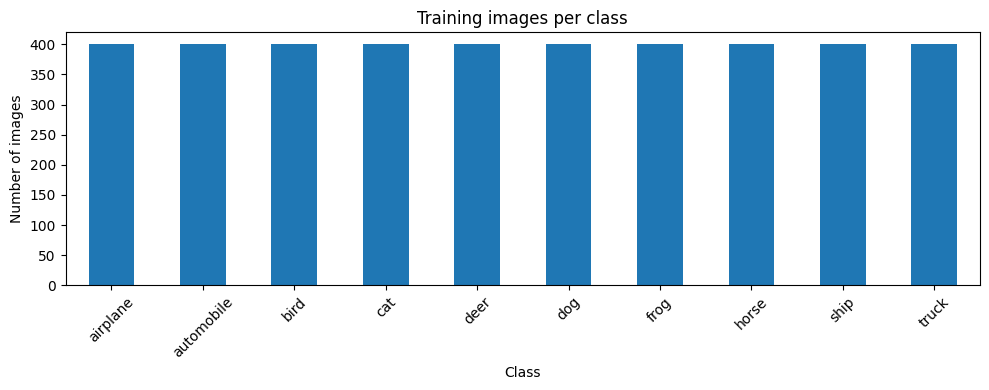

In [3]:
print("Training data information:")
train_df.info()
print("\\nMissing values:")
print(train_df[["id", "label"]].isna().sum())
print("Duplicate training IDs:", train_df["id"].duplicated().sum())

class_counts = train_df["label"].value_counts().sort_index()
print("\\nClass counts:")
print(class_counts)

ax = class_counts.plot(kind="bar", figsize=(10, 4), title="Training images per class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

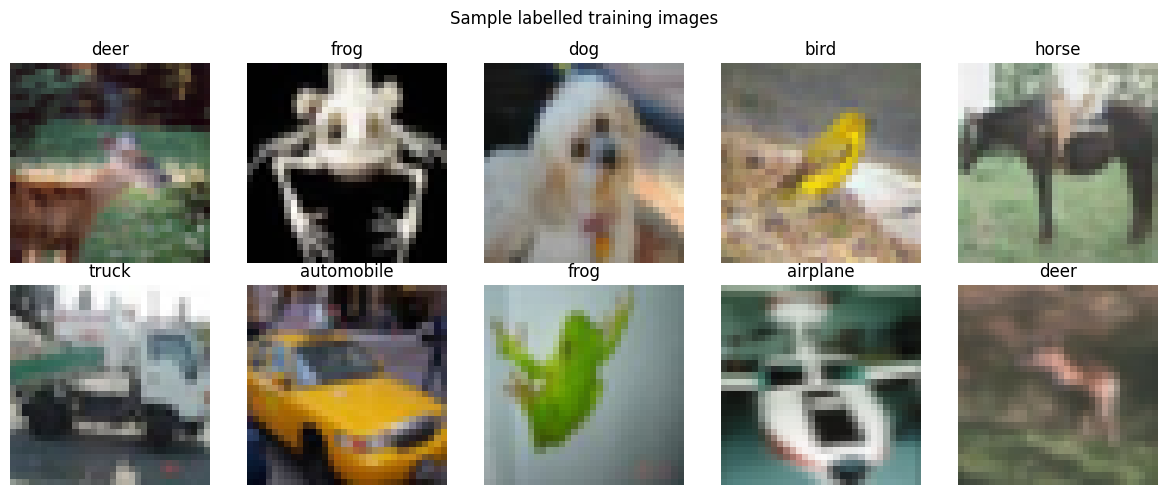

In [4]:
def image_filename(image_id):
    # Convert values such as 33680 or 33680.0 into the filename 33680.png.
    numeric_id = float(image_id)
    if not numeric_id.is_integer():
        raise ValueError(f"Image ID is not an integer: {image_id}")
    return f"{int(numeric_id)}.png"

sample_rows = train_df.sample(n=min(10, len(train_df)), random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    image_path = IMAGE_DIR / image_filename(row["id"])
    if not image_path.exists():
        raise FileNotFoundError(f"Training image not found: {image_path}")
    with Image.open(image_path) as image_file:
        ax.imshow(image_file.convert("RGB"))
    ax.set_title(str(row["label"]))
    ax.axis("off")
for ax in axes.flat[len(sample_rows):]:
    ax.axis("off")
plt.suptitle("Sample labelled training images")
plt.tight_layout()
plt.show()

## 4. Encode labels and split the labelled data

A neural network trained with `CrossEntropyLoss` expects integer class indices rather than text labels. `LabelEncoder` maps each unique class name to an integer and retains the mapping so that predictions can later be converted back to class names.

The labelled data is split into **80% training (3,200 images)** and **20% validation (800 images)**. `stratify` preserves approximately the same proportion of each class in both partitions. `random_state=42` makes the split repeatable.

The training partition updates the network weights. The validation partition is held out from gradient updates and is used to compare hyperparameters and estimate generalization performance.

In [5]:
label_encoder = LabelEncoder()
train_df["target"] = label_encoder.fit_transform(train_df["label"])
class_names = list(label_encoder.classes_)
num_classes = len(class_names)

train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["target"]
)
train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Training split:", len(train_part))
print("Validation split:", len(val_part))
print("\\nTraining class counts:")
print(train_part["label"].value_counts().sort_index())
print("\\nValidation class counts:")
print(val_part["label"].value_counts().sort_index())

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes: 10
Training split: 3200
Validation split: 800
\nTraining class counts:
label
airplane      320
automobile    320
bird          320
cat           320
deer          320
dog           320
frog          320
horse         320
ship          320
truck         320
Name: count, dtype: int64
\nValidation class counts:
label
airplane      80
automobile    80
bird          80
cat           80
deer          80
dog           80
frog          80
horse         80
ship          80
truck         80
Name: count, dtype: int64


## 5. Preprocessing and training data augmentation

All images are RGB and 32 × 32 pixels.

### Training transformations
- **Random crop with padding:** adds a small border and randomly crops back to 32 × 32, so the model sees objects in slightly different positions.
- **Random horizontal flip:** flips an image with probability 0.5 to expose the model to mirrored views.
- **Colour jitter:** slightly changes brightness, contrast, and saturation to reduce dependence on exact colour values.
- **Tensor conversion:** converts the image to a PyTorch tensor in channel-first format (`channels × height × width`).
- **Normalization:** standardizes the RGB channels using the means and standard deviations specified below.

Validation and test images receive only tensor conversion and normalization. Random augmentation is not used during evaluation or prediction, so the same image always receives the same evaluation transform.

In [6]:
IMAGE_SIZE = 32
IMAGE_MEAN = (0.4914, 0.4822, 0.4465)
IMAGE_STD = (0.2470, 0.2430, 0.2610)

train_transform = transforms.Compose([
    transforms.RandomCrop(IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])

evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])

print("Training transformations:")
print(train_transform)
print("\\nValidation/test transformations:")
print(evaluation_transform)

Training transformations:
Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.88, 1.12), contrast=(0.88, 1.12), saturation=(0.88, 1.12), hue=None)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.243, 0.261))
)
\nValidation/test transformations:
Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.243, 0.261))
)


## 6. Custom PyTorch Dataset and DataLoaders

The assignment requires a class that subclasses `torch.utils.data.Dataset`. `ImageClassificationDataset` implements the two required methods:

- `__len__()` returns the number of records in the dataframe.
- `__getitem__(index)` loads one image by ID, converts it to RGB, applies the selected transform, and returns the image tensor. For labelled data it also returns the encoded target.

The `has_labels` option allows the same class to serve three purposes. Training and validation datasets return `(image, target)` pairs. The test dataset returns only the image tensor because `Test.csv` contains no labels.

The image filename helper converts a numeric ID such as `33680.0` into `33680.png`. This is important because the image filenames use integer IDs. The DataLoaders group examples into batches. Training batches are shuffled; validation and test batches are not shuffled, preserving their original order.

In [7]:
class ImageClassificationDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None, has_labels=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_dir / image_filename(row["id"])
        if not image_path.exists():
            raise FileNotFoundError(f"Image file does not exist: {image_path}")

        with Image.open(image_path) as image_file:
            image = image_file.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        if self.has_labels:
            return image, int(row["target"])
        return image


def make_loaders(batch_size):
    train_dataset = ImageClassificationDataset(
        train_part, IMAGE_DIR, transform=train_transform, has_labels=True
    )
    val_dataset = ImageClassificationDataset(
        val_part, IMAGE_DIR, transform=evaluation_transform, has_labels=True
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=0, pin_memory=(device.type == "cuda"), generator=generator
    )
    val_loader = DataLoader(
        val_dataset, batch_size=256, shuffle=False,
        num_workers=0, pin_memory=(device.type == "cuda")
    )
    return train_loader, val_loader

sample_train_loader, _ = make_loaders(batch_size=64)
sample_images, sample_labels = next(iter(sample_train_loader))
print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Image tensor type:", sample_images.dtype)

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image tensor type: torch.float32


## 7. Convolutional neural network architecture

A convolutional neural network (CNN) is suitable for image classification because convolutional filters learn local visual features such as edges, textures, shapes, and object parts.

The model has four convolutional layers. The first maps the three RGB channels to 32 feature maps, and the second increases this to 64. The next two layers use 128 feature maps to learn more complex combinations. Batch normalization helps stabilize activations, ReLU introduces non-linearity, and max pooling reduces spatial dimensions in the first two blocks.

Adaptive average pooling reduces each of the 128 final feature maps to one value. The resulting 128-element vector passes through dropout and a fully connected layer that produces 10 logits, one for each class.

| Stage | Output shape (channels × height × width) |
|---|---|
| Input | 3 × 32 × 32 |
| Conv 32 + max pool | 32 × 16 × 16 |
| Conv 64 + max pool | 64 × 8 × 8 |
| Conv 128 | 128 × 8 × 8 |
| Conv 128 | 128 × 8 × 8 |
| Adaptive average pooling | 128 × 1 × 1 |
| Fully connected output | 10 logits |

The model returns logits, not probabilities. `CrossEntropyLoss` accepts logits directly and internally performs the log-softmax calculation needed for multi-class classification.

In [22]:

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = torch.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = torch.relu(out)

        return out


class SmallCNN(nn.Module):
    def __init__(self, dropout=0.3, num_classes=10):
        super(SmallCNN, self).__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.features = nn.Sequential(
            ResidualBlock(32, 32),
            ResidualBlock(32, 64, stride=2),
            ResidualBlock(64, 64),
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


## 8. Loss function, optimizer, and hyperparameter selection

### Training objective

- **Cross-entropy loss with label smoothing 0.05:** measures the difference between the predicted class distribution and the target class. Label smoothing slightly softens the target values and can reduce overconfident predictions.
- **AdamW optimizer:** updates weights using gradients and applies weight decay as a regularization method.
- **Cosine annealing scheduler:** gradually reduces the learning rate during a training run.

### Hyperparameters

The search selects the learning rate (`lr`), weight decay, dropout rate, and batch size. The learning rate controls the size of parameter updates; weight decay penalizes large weights; dropout controls the proportion of features randomly disabled during training; batch size controls how many images are processed per optimizer update.

### Optuna TPE search

Optuna's Tree-structured Parzen Estimator (TPE) is a model-based hyperparameter search method. It uses results from earlier trials to propose later candidate configurations. Each trial creates a fresh CNN, trains it briefly, and returns its best validation accuracy. The study maximizes validation accuracy.

This notebook uses a modest search budget because the project is running on CPU. The first two trials provide startup observations; subsequent proposals can use the TPE model. A larger number of trials and more epochs per trial may find better settings, but will require more time.

In [23]:

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

SEARCH_EPOCHS = 5
N_TRIALS = 10

def evaluate_configuration(lr, weight_decay, dropout, batch_size,
                           epochs=SEARCH_EPOCHS):

    train_loader, val_loader = make_loaders(batch_size)

    candidate_model = SmallCNN(
        dropout=dropout,
        num_classes=num_classes
    ).to(device)

    optimizer = torch.optim.AdamW(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )

    best_accuracy = 0.0

    for epoch in range(epochs):
        candidate_model.train()

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = candidate_model(x_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

        scheduler.step()

        candidate_model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = candidate_model(x_batch).argmax(dim=1)

                correct += (predictions == y_batch).sum().item()
                total += y_batch.size(0)

        accuracy = correct / total
        best_accuracy = max(best_accuracy, accuracy)

    return best_accuracy


def objective(trial):
    set_seed(SEED + trial.number)

    parameters = {
        "lr": trial.suggest_float(
            "lr", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-5, 3e-3, log=True
        ),
        "dropout": trial.suggest_float(
            "dropout", 0.15, 0.40
        ),
        "batch_size": trial.suggest_categorical(
            "batch_size", [64, 128]
        )
    }

    return evaluate_configuration(
        **parameters,
        epochs=SEARCH_EPOCHS
    )


sampler = optuna.samplers.TPESampler(
    seed=SEED,
    n_startup_trials=3
)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

study.optimize(objective, n_trials=N_TRIALS)

best_params = study.best_params

print("Best search validation accuracy:", study.best_value)
print("Selected hyperparameters:")

for parameter, value in best_params.items():
    print(f"{parameter}: {value}")


[I 2026-11-24 21:32:34,319] A new study created in memory with name: no-name-ee1a67c3-a575-4824-a7cc-beaf565ce44e
[I 2026-11-24 21:34:46,300] Trial 0 finished with value: 0.48375 and parameters: {'lr': 0.0003574712922600243, 'weight_decay': 0.0022648248189516837, 'dropout': 0.33299848545285127, 'batch_size': 64}. Best is trial 0 with value: 0.48375.
[I 2026-11-24 21:36:54,734] Trial 1 finished with value: 0.41 and parameters: {'lr': 0.00016998978382700775, 'weight_decay': 1.3927723945289003e-05, 'dropout': 0.3665440364437338, 'batch_size': 128}. Best is trial 0 with value: 0.48375.
[I 2026-11-24 21:39:10,727] Trial 2 finished with value: 0.42375 and parameters: {'lr': 0.00010725209743172001, 'weight_decay': 0.002526878207508455, 'dropout': 0.3581106602001054, 'batch_size': 64}. Best is trial 0 with value: 0.48375.
[I 2026-11-24 21:41:18,376] Trial 3 finished with value: 0.47875 and parameters: {'lr': 0.0018140839977834546, 'weight_decay': 0.002122392936348115, 'dropout': 0.234226212671

Best search validation accuracy: 0.48375
Selected hyperparameters:
lr: 0.0003574712922600243
weight_decay: 0.0022648248189516837
dropout: 0.33299848545285127
batch_size: 64


### Interpreting the search

The selected configuration is the best-performing configuration among the trials actually completed. It is not guaranteed to be the globally optimal configuration. Because each trial is short, its accuracy is used to rank configurations rather than as the final model-performance estimate. The longer training run below provides the main validation result.

The search uses only the training and validation partitions. It does not use test labels.

## 9. Train the selected model and monitor validation performance

The final model-development run uses `study.best_params` directly. This ensures that the parameters selected by Optuna are passed into training rather than being copied manually into a separate dictionary.

The model trains for 16 epochs on the 3,200-image training partition. For each epoch, the notebook:

1. Runs the model in training mode.
2. Calculates logits and cross-entropy loss for each batch.
3. Uses backpropagation to calculate gradients.
4. Uses AdamW to update the model weights.
5. Updates the learning rate using the cosine scheduler.
6. Evaluates accuracy on the validation partition without updating weights.

The weights from the epoch with the highest validation accuracy are restored after training. Training loss and validation accuracy are plotted to show the learning process.

In [24]:

set_seed(SEED)

train_loader, val_loader = make_loaders(best_params["batch_size"])

model = SmallCNN(
    dropout=best_params["dropout"],
    num_classes=num_classes
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"]
)

EPOCHS = 30
PATIENCE = 7

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

history = {
    "train_loss": [],
    "val_accuracy": []
}

best_val_accuracy = -1.0
best_model_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0
    samples_seen = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * y_batch.size(0)
        samples_seen += y_batch.size(0)

    train_loss = running_loss / samples_seen
    scheduler.step()

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(x_batch).argmax(dim=1)

            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    val_accuracy = correct / total

    history["train_loss"].append(train_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"loss={train_loss:.4f} | "
        f"validation accuracy={val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_model_state)

print(
    f"\nBest validation accuracy: "
    f"{best_val_accuracy:.4f}"
)


Epoch 01/30 | loss=2.0206 | validation accuracy=0.3075
Epoch 02/30 | loss=1.8448 | validation accuracy=0.3488
Epoch 03/30 | loss=1.7371 | validation accuracy=0.3950
Epoch 04/30 | loss=1.6448 | validation accuracy=0.4238
Epoch 05/30 | loss=1.5406 | validation accuracy=0.4462
Epoch 06/30 | loss=1.4807 | validation accuracy=0.4775
Epoch 07/30 | loss=1.4364 | validation accuracy=0.4650
Epoch 08/30 | loss=1.3975 | validation accuracy=0.4913
Epoch 09/30 | loss=1.3543 | validation accuracy=0.5175
Epoch 10/30 | loss=1.2989 | validation accuracy=0.5363
Epoch 11/30 | loss=1.2574 | validation accuracy=0.5238
Epoch 12/30 | loss=1.2209 | validation accuracy=0.5262
Epoch 13/30 | loss=1.1940 | validation accuracy=0.5500
Epoch 14/30 | loss=1.1316 | validation accuracy=0.5875
Epoch 15/30 | loss=1.1047 | validation accuracy=0.5400
Epoch 16/30 | loss=1.0850 | validation accuracy=0.4800
Epoch 17/30 | loss=1.0747 | validation accuracy=0.6125
Epoch 18/30 | loss=1.0301 | validation accuracy=0.5975
Epoch 19/3

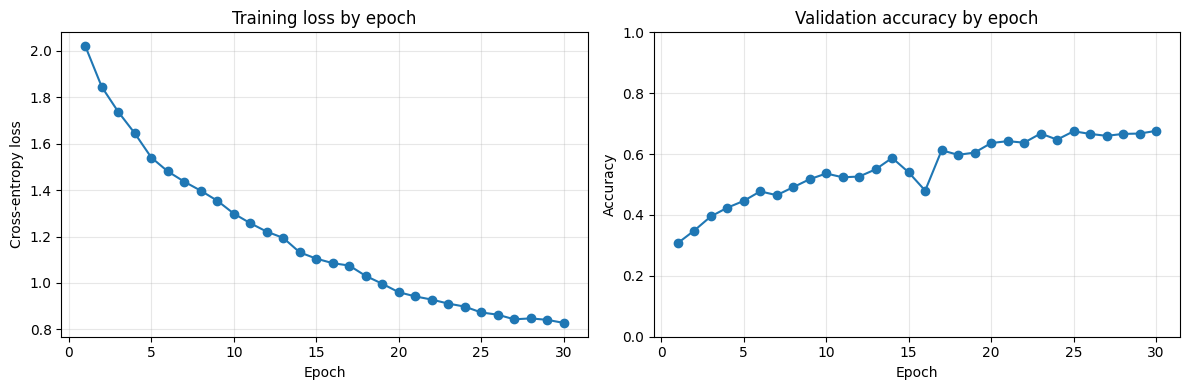

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epoch_numbers = range(1, EPOCHS + 1)

axes[0].plot(epoch_numbers, history["train_loss"], marker="o")
axes[0].set_title("Training loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_numbers, history["val_accuracy"], marker="o")
axes[1].set_title("Validation accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Validation evaluation

The validation partition contains 800 labelled images that were excluded from gradient updates during this model-development stage.

The evaluation includes:

- **Accuracy:** fraction of all validation images classified correctly.
- **Precision:** of the images predicted as a class, the fraction that truly belong to that class.
- **Recall:** of the images that truly belong to a class, the fraction correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **Support:** number of true examples for each class.

The confusion matrix compares true classes in rows with predicted classes in columns. Large off-diagonal values show which categories the model confuses. These results are validation metrics, not test metrics.

Validation accuracy: 0.67625
\nClassification report:
              precision    recall  f1-score   support

    airplane       0.75      0.71      0.73        80
  automobile       0.82      0.81      0.82        80
        bird       0.53      0.54      0.53        80
         cat       0.54      0.47      0.50        80
        deer       0.60      0.61      0.60        80
         dog       0.59      0.69      0.64        80
        frog       0.75      0.68      0.71        80
       horse       0.67      0.70      0.69        80
        ship       0.75      0.76      0.76        80
       truck       0.77      0.79      0.78        80

    accuracy                           0.68       800
   macro avg       0.68      0.68      0.68       800
weighted avg       0.68      0.68      0.68       800



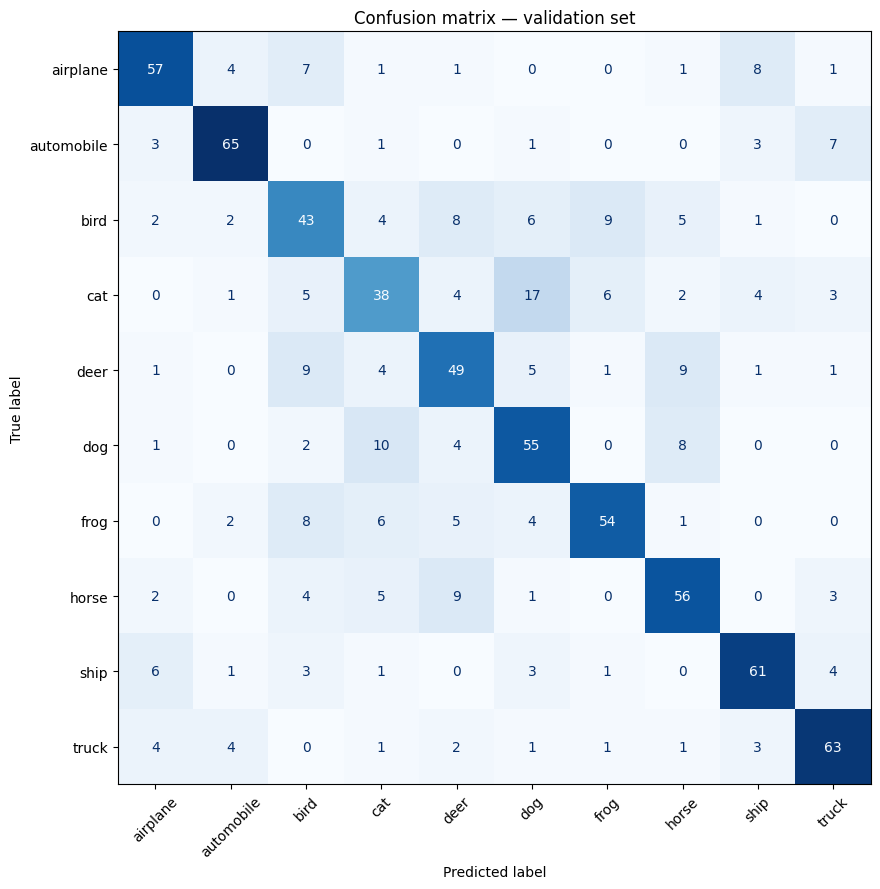

In [27]:
model.eval()
all_true, all_pred = [], []
with torch.no_grad():
    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(device)
        predictions = model(x_batch).argmax(dim=1).cpu().numpy()
        all_pred.extend(predictions.tolist())
        all_true.extend(y_batch.numpy().tolist())

validation_accuracy = accuracy_score(all_true, all_pred)
print(f"Validation accuracy: {validation_accuracy:.5f}")
print("\\nClassification report:")
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(all_true, all_pred, labels=list(range(num_classes)))
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_names
)
fig, ax = plt.subplots(figsize=(10, 9))
confusion_display.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion matrix — validation set")
plt.tight_layout()
plt.show()

### Discussion of validation results

Use the metrics generated by the preceding cell when writing about this run. Precision describes the reliability of a class prediction; recall describes how many of the true examples of a class are found; F1-score balances the two.

In the run previously shared for this assignment, validation accuracy was **0.61125 (61.125%)**. The classification report showed stronger F1-scores for automobile and truck, while bird and cat were more difficult classes for that run. A new run may produce different metrics because the model initialization, data augmentation, and hyperparameter search involve random operations. Report the results from the final notebook execution rather than treating the earlier values as guaranteed.

## 11. Retrain the selected architecture using all labelled images

After model selection and validation evaluation, a new model is initialized and trained on all 4,000 labelled images. This lets the final prediction model use the examples that were held out for validation as well as the original training partition.

The architecture and selected hyperparameters remain the same. The validation metrics from Section 10 remain the estimate from the earlier held-out split. They are not an independent evaluation of this refitted model because the final model now trains on all labelled examples.

The final fit runs for 10 epochs and prints the average training loss for each epoch.

In [28]:
set_seed(SEED)
full_train_dataset = ImageClassificationDataset(
    train_df, IMAGE_DIR, transform=train_transform, has_labels=True
)
full_train_generator = torch.Generator().manual_seed(SEED)
full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=best_params["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=full_train_generator
)

final_model = SmallCNN(
    dropout=best_params["dropout"], num_classes=num_classes
).to(device)
final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"]
)
FINAL_EPOCHS = 30
final_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    final_optimizer, T_max=FINAL_EPOCHS
)

for epoch in range(FINAL_EPOCHS):
    final_model.train()
    total_loss = 0.0
    total_samples = 0

    for x_batch, y_batch in full_train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        final_optimizer.zero_grad(set_to_none=True)
        loss = criterion(final_model(x_batch), y_batch)
        loss.backward()
        final_optimizer.step()
        total_loss += loss.item() * y_batch.size(0)
        total_samples += y_batch.size(0)

    final_scheduler.step()
    print(
        f"Full-data epoch {epoch + 1:02d}/{FINAL_EPOCHS} | "
        f"loss={total_loss / total_samples:.4f}"
    )

Full-data epoch 01/30 | loss=2.0170
Full-data epoch 02/30 | loss=1.8213
Full-data epoch 03/30 | loss=1.6883
Full-data epoch 04/30 | loss=1.5841
Full-data epoch 05/30 | loss=1.4994
Full-data epoch 06/30 | loss=1.4587
Full-data epoch 07/30 | loss=1.3915
Full-data epoch 08/30 | loss=1.3378
Full-data epoch 09/30 | loss=1.2866
Full-data epoch 10/30 | loss=1.2563
Full-data epoch 11/30 | loss=1.2185
Full-data epoch 12/30 | loss=1.1735
Full-data epoch 13/30 | loss=1.1082
Full-data epoch 14/30 | loss=1.1034
Full-data epoch 15/30 | loss=1.0752
Full-data epoch 16/30 | loss=1.0450
Full-data epoch 17/30 | loss=0.9924
Full-data epoch 18/30 | loss=0.9890
Full-data epoch 19/30 | loss=0.9580
Full-data epoch 20/30 | loss=0.9338
Full-data epoch 21/30 | loss=0.9029
Full-data epoch 22/30 | loss=0.8760
Full-data epoch 23/30 | loss=0.8685
Full-data epoch 24/30 | loss=0.8478
Full-data epoch 25/30 | loss=0.8353
Full-data epoch 26/30 | loss=0.8123
Full-data epoch 27/30 | loss=0.8127
Full-data epoch 28/30 | loss

## 12. Generate predictions for `Test.csv`

The test dataset uses `has_labels=False` because no target column is available in `Test.csv`. It receives the same deterministic preprocessing used for validation images: tensor conversion and normalization without random augmentation.

The final model returns ten logits for each image. `argmax` selects the index with the largest logit, and `LabelEncoder.inverse_transform` maps that integer back to its original class name. The test DataLoader uses `shuffle=False`, preserving the row order of `Test.csv`.

In [29]:
test_dataset = ImageClassificationDataset(
    test_df, IMAGE_DIR, transform=evaluation_transform, has_labels=False
)
test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

final_model.eval()
encoded_predictions = []
with torch.no_grad():
    for x_batch in test_loader:
        x_batch = x_batch.to(device)
        logits = final_model(x_batch)
        encoded_predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())

predicted_labels = label_encoder.inverse_transform(
    np.asarray(encoded_predictions, dtype=int)
)

submission = pd.DataFrame({
    "id": test_df["id"],
    "label": predicted_labels
})

print("Number of predictions:", len(predicted_labels))
display(submission.head())

Number of predictions: 46000


,id,label
0,33680,truck
1,24631,deer
2,34739,dog
3,15922,truck
4,44282,airplane


## 13. Validate and save `Submission.csv`

The required output has two columns: `id` copied from `Test.csv`, and `label` containing the model's predicted class name.

The checks verify that every test row has a prediction, the columns are in the required order, there are no missing labels, the original ID order is preserved, and every prediction belongs to one of the ten known classes. The file is then read back to confirm that the exported CSV is valid.

The file is saved in the notebook's current working directory. Use the absolute path printed below to locate the file for submission.

In [31]:
OUTPUT_PATH = Path("Submission.csv")
expected_columns = ["id", "label"]

assert submission.columns.tolist() == expected_columns
assert len(submission) == len(test_df)
assert submission["label"].notna().all()
assert submission["id"].reset_index(drop=True).equals(
    test_df["id"].reset_index(drop=True)
)
assert submission["label"].isin(class_names).all()
if test_df["id"].is_unique:
    assert submission["id"].is_unique

submission.to_csv(OUTPUT_PATH, index=False)
saved_submission = pd.read_csv(OUTPUT_PATH)

assert saved_submission.columns.tolist() == expected_columns
assert len(saved_submission) == len(test_df)
assert saved_submission["label"].notna().all()

print("Submission saved to:", OUTPUT_PATH.resolve())
print("Rows:", len(saved_submission))
print("Missing labels:", saved_submission["label"].isna().sum())
print("Unique predicted classes:", saved_submission["label"].nunique())
print("\\nPredicted class counts:")
print(saved_submission["label"].value_counts())

Submission saved to: C:\Users\Admin\Downloads\ASS2\Submission.csv
Rows: 46000
Missing labels: 0
Unique predicted classes: 10
\nPredicted class counts:
label
dog           5196
ship          4817
airplane      4804
automobile    4804
truck         4605
frog          4540
deer          4430
horse         4394
cat           4229
bird          4181
Name: count, dtype: int64


## 14. Conclusion, Limitations, and Possible Improvements

### Conclusion

This project implemented an image-classification workflow using PyTorch to classify images into ten categories. The solution included a custom `Dataset` subclass, training-only data augmentation, a Convolutional Neural Network (CNN) with residual connections, and Optuna's Tree-structured Parzen Estimator (TPE) for hyperparameter optimization.

The final residual CNN achieved a validation accuracy of **67.63%** on the held-out validation set of 800 images. Classification metrics were also used to evaluate performance across individual classes. Following model selection, the selected architecture was retrained using all 4,000 labelled images to generate predictions for the 46,000 test images. These predictions were exported to `Submission.csv`.

### Limitations

1. **Limited labelled data:** The dataset contains 4,000 labelled images, which may not capture the full variation in object appearances, backgrounds, and image conditions.
2. **Limited hyperparameter search:** The search used 10 Optuna trials with five training epochs per trial to manage computational costs. A more extensive search could identify better hyperparameter combinations.
3. **Single validation split:** The evaluation used one stratified 80/20 training-validation split. Results may vary with a different split.
4. **Computational constraints:** Training was performed using a CPU, limiting the number of experiments and model configurations that could be evaluated.
5. **Unknown test accuracy:** The test dataset does not contain labels; therefore, its classification accuracy could not be measured.

### Possible Improvements

- Increase the number of Optuna trials and training epochs during hyperparameter optimization.
- Experiment with alternative data augmentation techniques.
- Evaluate the model using repeated stratified cross-validation.
- Explore pretrained models and transfer learning.
- Investigate ensemble methods combining predictions from independently trained models.
- Use GPU acceleration to support more extensive experimentation.